# Guide des visualisations de données Python avec Seaborn et Matplotlib

Notebook de l'article [Guide des visualisations de données Python avec Seaborn et Matplotlib](https://moncoachdata.com/blog/guide-visualisations-de-donnees-python/) (MonCoachData).

Exécute les cellules **dans l'ordre**. Le code est testé avec Matplotlib 3.11, Seaborn 0.13 et Pandas 3 (mêmes résultats avec Pandas 2). Les données du Black Friday sont chargées depuis le dépôt GitHub du blog : rien à télécharger.

## Matplotlib : interface fonctionnelle ou orientée objet ?

Dans Jupyter et dans Colab, les graphiques s'affichent automatiquement : pas besoin de `%matplotlib inline`.

In [1]:
import matplotlib.pyplot as plt

### La méthode fonctionnelle

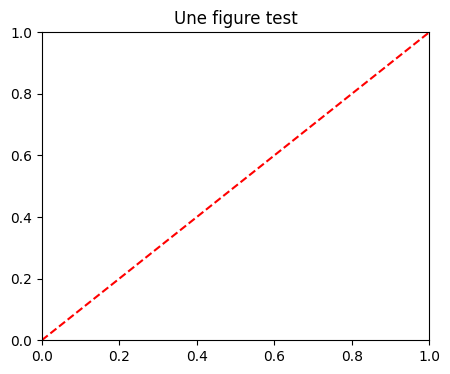

In [2]:
plt.figure(figsize=(5, 4))
plt.plot([0, 1], [0, 1], 'r--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.title('Une figure test')
plt.show()

### La méthode orientée objet

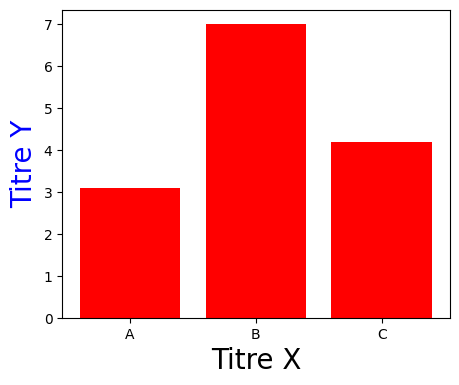

In [3]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(x=['A', 'B', 'C'], height=[3.1, 7, 4.2], color='r')
ax.set_xlabel('Titre X', size=20)
ax.set_ylabel('Titre Y', color='b', size=20)
plt.show()

## Les éléments d'une figure

Exemple de graphique linéaire avec l'interface orientée objet.

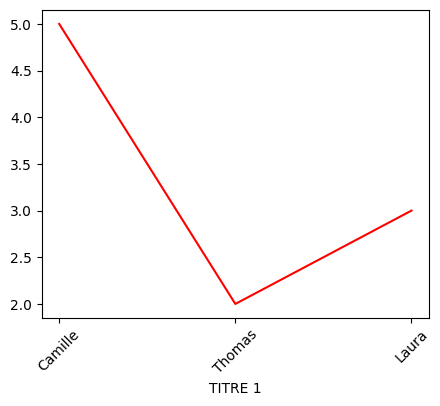

In [4]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(['Camille', 'Thomas', 'Laura'], [5, 2, 3], color='r')
ax.set_xlabel('TITRE 1')
ax.tick_params(axis='x', rotation=45)
plt.show()

## Quels types de graphiques utiliser avec Seaborn ?

On utilise deux petits jeux de données fournis avec Seaborn : `tips` (pourboires) et `flights` (passagers aériens).

In [5]:
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme()  # style par défaut de Seaborn

tips = sns.load_dataset("tips")
flights = sns.load_dataset("flights")
print(tips.head())

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4


### 1. Nuage de points

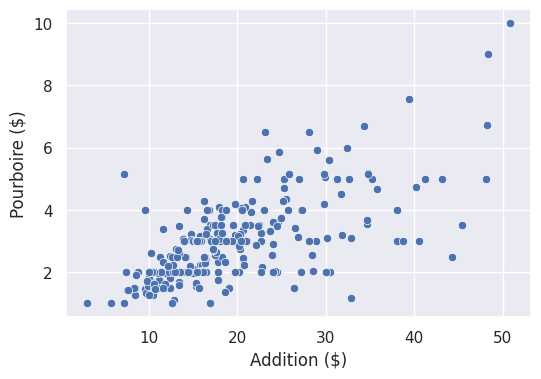

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.scatterplot(data=tips, x="total_bill", y="tip", ax=ax)
ax.set(xlabel="Addition ($)", ylabel="Pourboire ($)")
plt.show()

### 2. Tracé linéaire

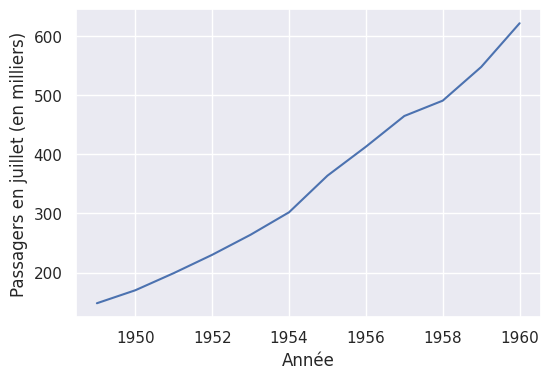

In [7]:
juillet = flights[flights["month"] == "Jul"]

fig, ax = plt.subplots(figsize=(6, 4))
sns.lineplot(data=juillet, x="year", y="passengers", ax=ax)
ax.set(xlabel="Année", ylabel="Passagers en juillet (en milliers)")
plt.show()

### 3. Diagramme à barres

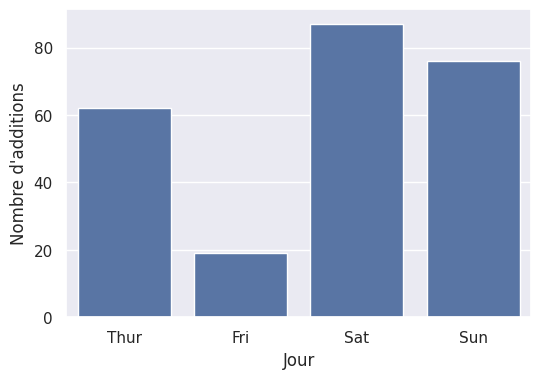

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=tips, x="day", ax=ax)
ax.set(xlabel="Jour", ylabel="Nombre d'additions")
plt.show()

### 4. Histogramme

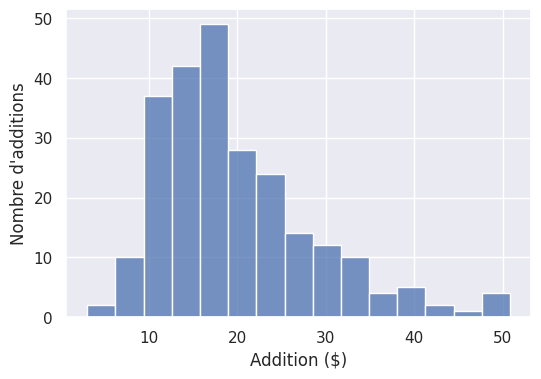

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(data=tips, x="total_bill", bins=15, ax=ax)
ax.set(xlabel="Addition ($)", ylabel="Nombre d'additions")
plt.show()

### 5. Densité du noyau (KDE)

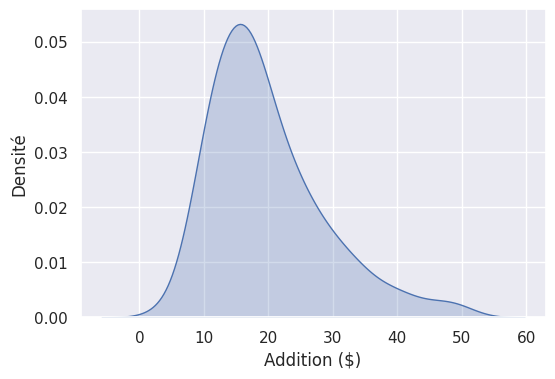

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.kdeplot(data=tips, x="total_bill", fill=True, ax=ax)
ax.set(xlabel="Addition ($)", ylabel="Densité")
plt.show()

### 6. Densité du noyau en 2D

La clé est l'argument `ax=ax` : Seaborn dessine dans l'objet `ax`.

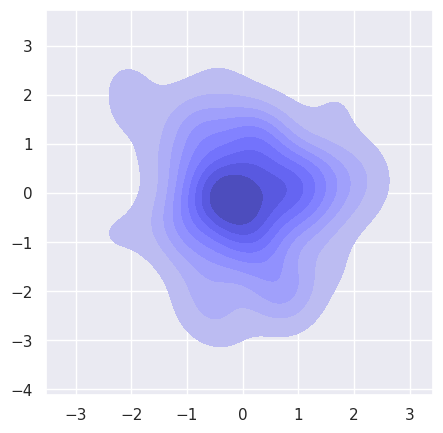

In [11]:
np.random.seed(1)
numerical_1 = np.random.randn(100)
np.random.seed(2)
numerical_2 = np.random.randn(100)

fig, ax = plt.subplots(figsize=(5, 5))
sns.kdeplot(x=numerical_1, y=numerical_2, ax=ax, fill=True, color="blue")
plt.show()

### 7. Boîte à moustaches

Avec Matplotlib 3.11, Seaborn 0.13 peut afficher un avertissement `vert: bool was deprecated` : il est sans conséquence sur le résultat.

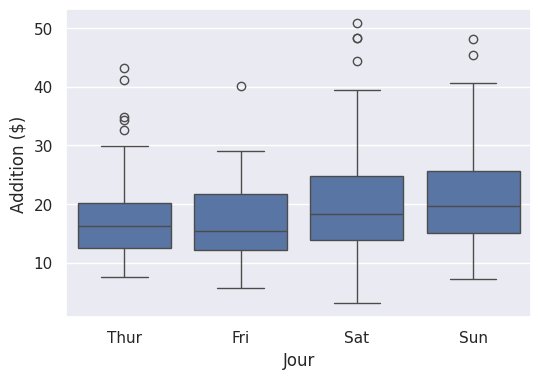

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=tips, x="day", y="total_bill", ax=ax)
ax.set(xlabel="Jour", ylabel="Addition ($)")
plt.show()

### 8. Diagramme en violon

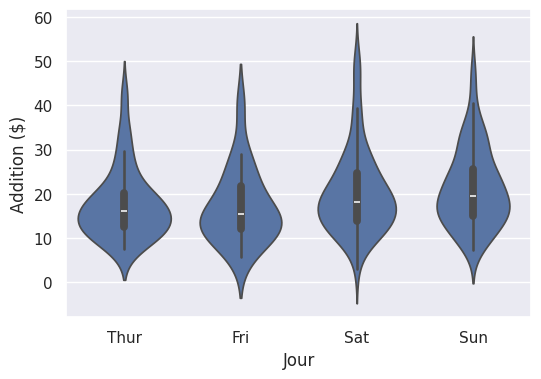

In [13]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.violinplot(data=tips, x="day", y="total_bill", ax=ax)
ax.set(xlabel="Jour", ylabel="Addition ($)")
plt.show()

### 9. Carte de chaleur

categorical_2   A   B  C
categorical_1           
apple          10   7  1
banana          2   3  6
grapes          5  15  8


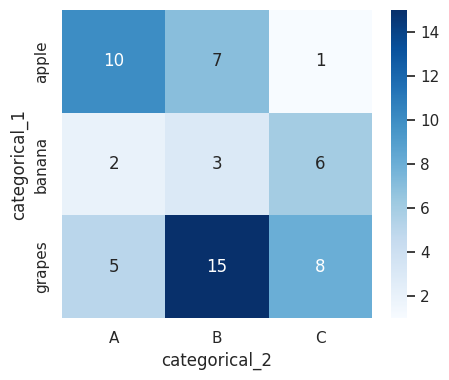

In [14]:
df = pd.DataFrame(dict(
    categorical_1=['apple', 'banana', 'grapes'] * 3,
    categorical_2=['A', 'A', 'A', 'B', 'B', 'B', 'C', 'C', 'C'],
    value=[10, 2, 5, 7, 3, 15, 1, 6, 8]))

pivot_table = df.pivot(index="categorical_1", columns="categorical_2", values="value")
print(pivot_table)

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(data=pivot_table, cmap="Blues", annot=True, ax=ax)
plt.show()

## Augmenter la dimension de tes graphiques

### Superposer des tracés

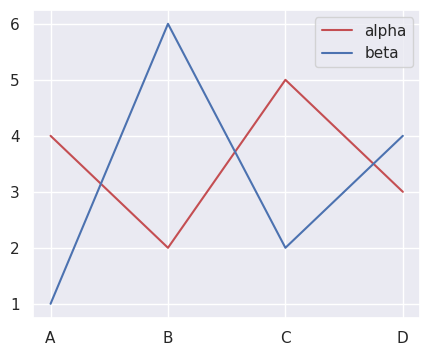

In [15]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.lineplot(x=['A', 'B', 'C', 'D'], y=[4, 2, 5, 3], color='r', label='alpha', ax=ax)
sns.lineplot(x=['A', 'B', 'C', 'D'], y=[1, 6, 2, 4], color='b', label='beta', ax=ax)
plt.show()

Un diagramme à barres et un tracé linéaire avec deux axes y (`twinx()`) :

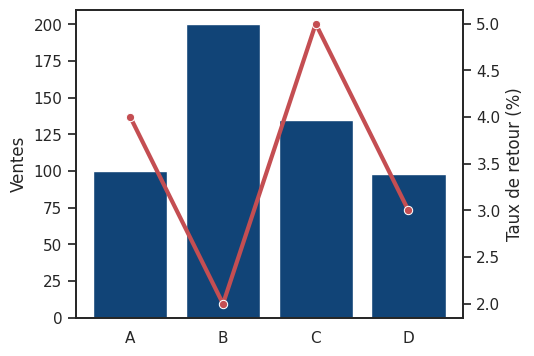

In [16]:
sns.set_theme(style="white", rc={"lines.linewidth": 3})

fig, ax1 = plt.subplots(figsize=(5, 4))
ax2 = ax1.twinx()

sns.barplot(x=['A', 'B', 'C', 'D'], y=[100, 200, 135, 98], color='#004488', ax=ax1)
sns.lineplot(x=['A', 'B', 'C', 'D'], y=[4, 2, 5, 3], color='r', marker="o", ax=ax2)

ax1.set_ylabel("Ventes")
ax2.set_ylabel("Taux de retour (%)")
plt.show()

sns.set_theme()  # retour au style par défaut

Diagramme à barres groupées, version « à la main » :

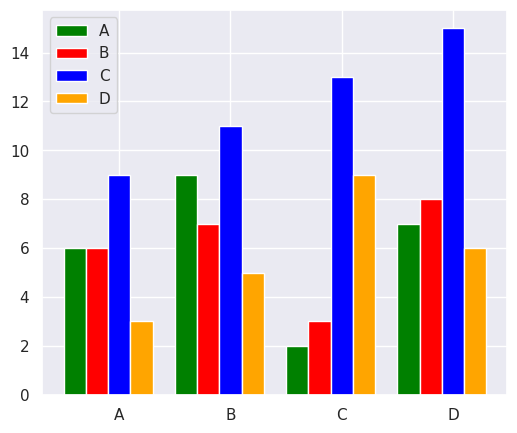

In [17]:
categorical_1 = ['A', 'B', 'C', 'D']
colors = ['green', 'red', 'blue', 'orange']
numerical = [[6, 9, 2, 7],
             [6, 7, 3, 8],
             [9, 11, 13, 15],
             [3, 5, 9, 6]]

number_groups = len(categorical_1)
bin_width = 1.0 / (number_groups + 1)

fig, ax = plt.subplots(figsize=(6, 5))

for i in range(number_groups):
    ax.bar(x=np.arange(len(categorical_1)) + i * bin_width,
           height=numerical[i],
           width=bin_width,
           color=colors[i],
           align='center')

# number_groups / (2 * (number_groups + 1)) : décalage des étiquettes de l'axe x
ax.set_xticks(np.arange(len(categorical_1)) + number_groups / (2 * (number_groups + 1)))
ax.set_xticklabels(categorical_1)
ax.legend(categorical_1)
plt.show()

Avec un DataFrame, l'argument `hue` fait le travail :

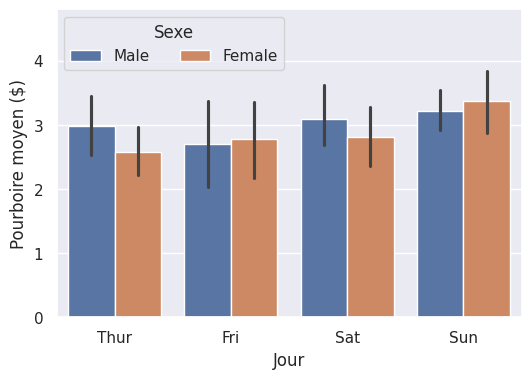

In [18]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(data=tips, x="day", y="tip", hue="sex", ax=ax)
ax.set(xlabel="Jour", ylabel="Pourboire moyen ($)", ylim=(0, 4.8))
ax.legend(title="Sexe", ncol=2, loc="upper left")
plt.show()

### Facettes

Les fonctions Seaborn « au niveau de la figure » (`relplot`, `displot`, `catplot`) créent leur propre figure : elles n'acceptent pas `ax=ax`.

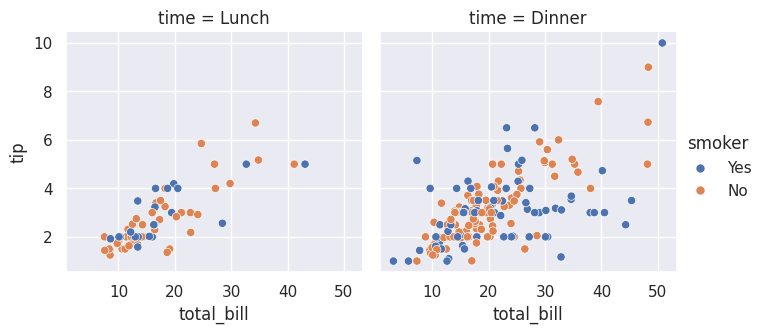

In [19]:
g = sns.relplot(data=tips, x="total_bill", y="tip",
                col="time", hue="smoker", height=3.5)
plt.show()

### Couleur, forme et taille des points

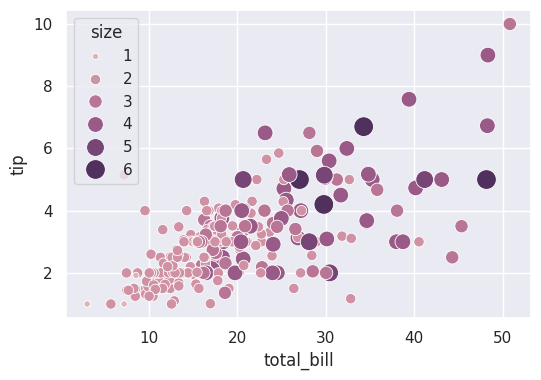

In [20]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.scatterplot(data=tips, x="total_bill", y="tip",
                hue="size", size="size", sizes=(20, 200),
                hue_norm=(0, 7), legend="full", ax=ax)
plt.show()

## Partitionner une figure : GridSpec et subplot_mosaic

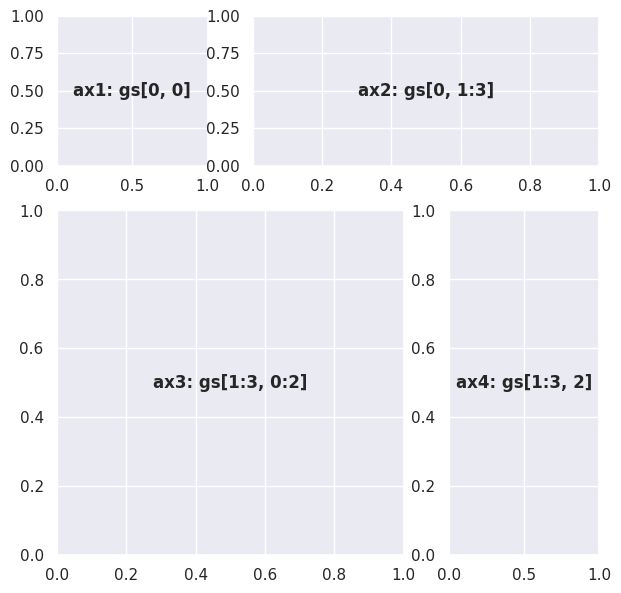

In [21]:
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(7, 7))

gs = gridspec.GridSpec(nrows=3, ncols=3, figure=fig,
                       width_ratios=[1, 1, 1],
                       height_ratios=[1, 1, 1],
                       wspace=0.3, hspace=0.3)

ax1 = fig.add_subplot(gs[0, 0])
ax1.text(0.5, 0.5, 'ax1: gs[0, 0]', fontsize=12, fontweight="bold", va="center", ha="center")

ax2 = fig.add_subplot(gs[0, 1:3])
ax2.text(0.5, 0.5, 'ax2: gs[0, 1:3]', fontsize=12, fontweight="bold", va="center", ha="center")

ax3 = fig.add_subplot(gs[1:3, 0:2])
ax3.text(0.5, 0.5, 'ax3: gs[1:3, 0:2]', fontsize=12, fontweight="bold", va="center", ha="center")

ax4 = fig.add_subplot(gs[1:3, 2])
ax4.text(0.5, 0.5, 'ax4: gs[1:3, 2]', fontsize=12, fontweight="bold", va="center", ha="center")

plt.show()

La même disposition avec `subplot_mosaic` :

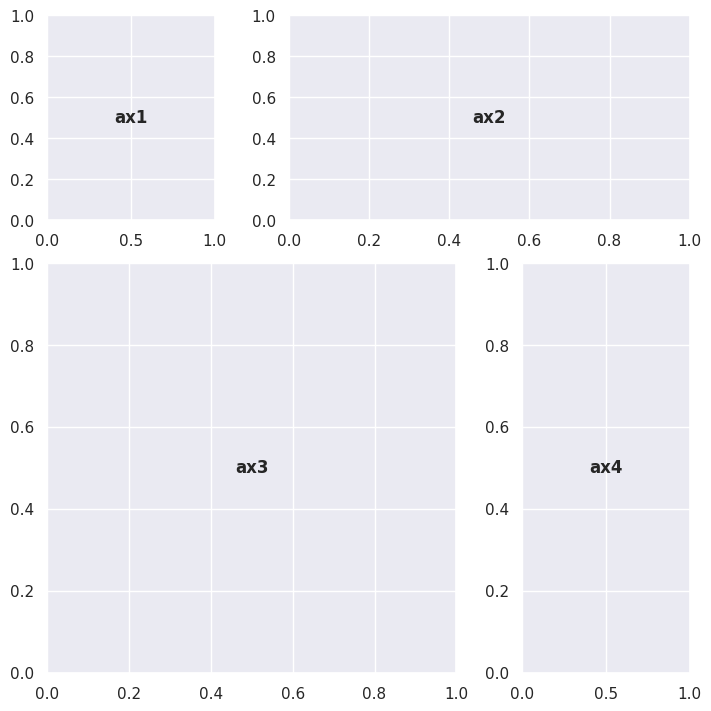

In [22]:
fig, axd = plt.subplot_mosaic([["ax1", "ax2", "ax2"],
                               ["ax3", "ax3", "ax4"],
                               ["ax3", "ax3", "ax4"]],
                              figsize=(7, 7), layout="constrained")

for nom, ax in axd.items():
    ax.text(0.5, 0.5, nom, fontsize=12, fontweight="bold", va="center", ha="center")

plt.show()

## Visualisation avancée : les ventes du Black Friday

Données : ventes du Black Friday d'un magasin, issues d'un concours Analytics Vidhya (550 068 achats). Le fichier est hébergé dans ce dépôt.

In [23]:
url = "https://raw.githubusercontent.com/moncoachdata/blog-data-science/main/guide-visualisations-de-donnees-python/black-friday.csv"
df = pd.read_csv(url, usecols=['User_ID', 'Gender', 'Age', 'Purchase'])
print(df.shape)
print(df.head())

(550068, 4)
   User_ID Gender   Age  Purchase
0  1000001      F  0-17      8370
1  1000001      F  0-17     15200
2  1000001      F  0-17      1422
3  1000001      F  0-17      1057
4  1000002      M   55+      7969


Chaque ligne est un achat : on regroupe par client (prix moyen, sexe, tranche d'âge).

In [24]:
# Un client = une ligne : prix moyen de ses achats, avec son sexe et sa tranche d'âge
df_gp = df.groupby('User_ID', as_index=False).agg(
    Purchase=('Purchase', 'mean'),
    Gender=('Gender', 'first'),
    Age=('Age', 'first'))

print(df_gp.shape)
print(df_gp.head())

(5891, 4)
   User_ID      Purchase Gender    Age
0  1000001   9545.514286      F   0-17
1  1000002  10525.610390      M    55+
2  1000003  11780.517241      M  26-35
3  1000004  14747.714286      M  46-50
4  1000005   7745.292453      M  26-35


Le sexe et la tranche d'âge sont-ils uniques pour chaque client ?

In [25]:
# Le sexe et l'âge sont-ils bien uniques pour chaque client ?
print(df.groupby('User_ID')[['Gender', 'Age']].nunique().max())

Gender    1
Age       1
dtype: int64


### Étape 1 : objectif

Comment l'âge et le sexe influencent-ils le montant moyen des achats ? Quelle est la répartition des montants ? Quel est le poids de chaque tranche d'âge ?

### Étape 2 : variables

Tranche d'âge, sexe, montant moyen et sa distribution (KDE), pourcentage de clients par tranche d'âge (barres).

In [26]:
print(df_gp.groupby('Gender')['Purchase'].mean().round(0))
print(df_gp['Age'].value_counts(normalize=True).sort_index().mul(100).round(1))

Gender
F    8965.0
M    9807.0
Name: Purchase, dtype: float64
Age
0-17      3.7
18-25    18.1
26-35    34.8
36-45    19.8
46-50     9.0
51-55     8.2
55+       6.3
Name: proportion, dtype: float64


### Étape 3 : la visualisation

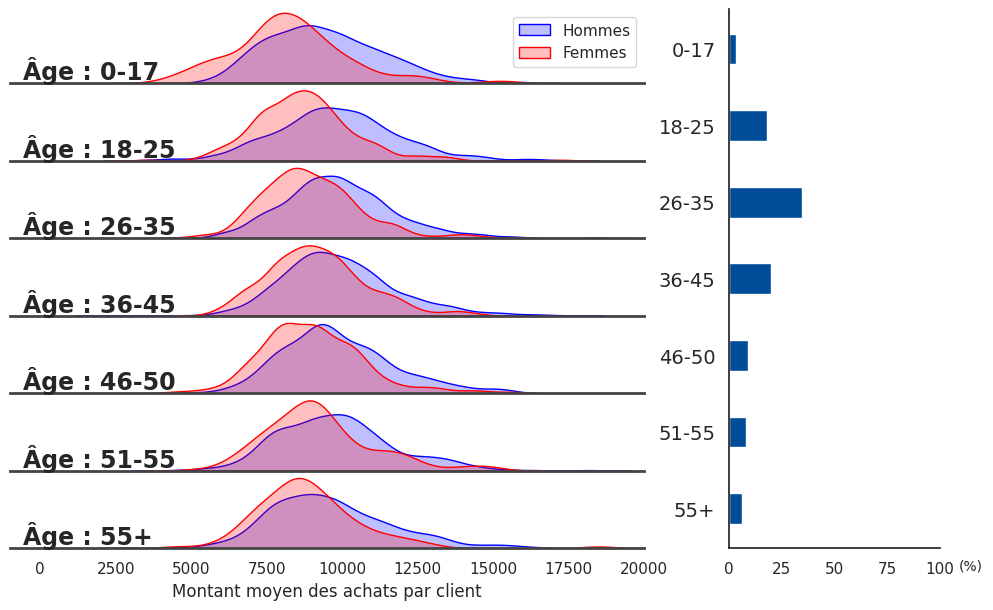

In [27]:
# Pourcentage de clients dans chaque tranche d'âge (7 tranches, triées)
freq = df_gp['Age'].value_counts(normalize=True).sort_index() * 100
age_groups = freq.index.tolist()
number_gp = len(age_groups)

def ax_settings(ax, var_name, x_min, x_max):
    ax.set_xlim(x_min, x_max)
    ax.set_yticks([])
    ax.set_ylabel('')

    ax.spines['left'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

    ax.spines['bottom'].set_edgecolor('#444444')
    ax.spines['bottom'].set_linewidth(2)

    ax.text(0.02, 0.05, var_name, fontsize=17, fontweight="bold", transform=ax.transAxes)

# Figure découpée en 7 lignes x 2 colonnes (3/4 de la largeur pour les KDE, 1/4 pour les barres)
sns.set_theme(style="white")
fig = plt.figure(figsize=(12, 7))
gs = gridspec.GridSpec(nrows=number_gp, ncols=2, figure=fig,
                       width_ratios=[3, 1], height_ratios=[1] * number_gp,
                       wspace=0.2, hspace=0.05)

ax = [None] * (number_gp + 1)

# Une ligne par tranche d'âge : une KDE pour les hommes (bleu), une pour les femmes (rouge)
for i in range(number_gp):
    ax[i] = fig.add_subplot(gs[i, 0])
    ax_settings(ax[i], 'Âge : ' + age_groups[i], -1000, 20000)

    hommes = df_gp[(df_gp.Gender == 'M') & (df_gp.Age == age_groups[i])]
    femmes = df_gp[(df_gp.Gender == 'F') & (df_gp.Age == age_groups[i])]
    sns.kdeplot(data=hommes, x='Purchase', ax=ax[i], fill=True, color="blue", bw_adjust=0.8, label='Hommes')
    sns.kdeplot(data=femmes, x='Purchase', ax=ax[i], fill=True, color="red", bw_adjust=0.8, label='Femmes')

    ax[i].set_ylabel('')
    if i < number_gp - 1:
        ax[i].set_xticks([])

ax[0].legend()
ax[number_gp - 1].set_xlabel('Montant moyen des achats par client')

# Colonne de droite : diagramme à barres horizontales des pourcentages
ax[number_gp] = fig.add_subplot(gs[:, 1])
ax[number_gp].spines['right'].set_visible(False)
ax[number_gp].spines['top'].set_visible(False)
ax[number_gp].barh(age_groups, freq, color='#004c99', height=0.4)
ax[number_gp].set_xlim(0, 100)
ax[number_gp].invert_yaxis()
ax[number_gp].text(1.09, -0.04, '(%)', fontsize=10, transform=ax[number_gp].transAxes)
ax[number_gp].tick_params(axis='y', labelsize=14)

plt.show()